In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib
from matplotlib import pyplot as plt
from scipy.fft import fft, fftfreq
from scipy import signal
import aotools
import matplotlib.ticker as mtick
from matplotlib.ticker import MultipleLocator, FuncFormatter, AutoMinorLocator
%matplotlib qt

In [2]:
def h2(p):
    q=1-p
    h2p=((-p)*np.log2(p))-(q*np.log2(q))
    return h2p

In [6]:
#C3: Unspliced

plt.rcParams.update({'font.size': 10})
plt.rc('axes', titlesize=16)
plt.rc('axes', labelsize=14) 
fig, ax = plt.subplots()
fig.set_size_inches(8, 6)

E=np.linspace(0.00001,0.12,101)
R=1-(2*h2(E))

boby=1-h2(E)
evey=h2(E)

ax.plot(E, R)
ax.plot(E, boby)
ax.plot(E, evey)
#ax.loglog(DM5MsZ7_1_f, DM5MsZ7_1_Pxx, label='5 MS/s')
#ax.loglog(DM50MsZ7_1_f, DM50MsZ7_1_Pxx, label='50 MS/s')
#ax.loglog(DM500MsZ7_1_f, DM500MsZ7_1_Pxx, label='500 MS/s')
#ax.axvline(x=a, linestyle='--', color='k', alpha=0.45, linewidth = '1')
#ax.axvline(x=b, linestyle='--', color='k', alpha=0.45, linewidth = '1')
#ax.axvline(x=c, linestyle='--', color='k', alpha=0.45, linewidth = '1')
ax.set_xlabel('$E$ [per bit]')
ax.set_ylabel('$R(E)$[per bit]')
#ax.set_ylabel('PSD [$1/U (10^5 V ^{-1} )$]')
ax.set_xlim(0, 0.12)
ax.set_ylim(0, 1)
#ax.set_ylim([1*(10**(-12)),1*(10**(-1))])

#ax.indicate_inset([x_1,y_1,(x_2-x_1),(y_2-y_1)],label='_nolegend_')
ax.set_title('Secret key rate per QBER plot')
plt.legend(loc='upper right', fontsize="14")
#plt.savefig('.pdf', dpi=300)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


In [8]:
plt.rcParams.update({'font.size': 12})
plt.rc('axes', titlesize=18)
plt.rc('axes', labelsize=16) 
fig, ax = plt.subplots(2,1, gridspec_kw={'height_ratios': [2, 1]})

ax[0].plot(E,R, label='Secret key rate', linewidth = '2')
ax[1].plot(E, boby,color='tab:orange', label='Bob: $1-h_{2}(Q)$', linewidth = '1.5')
ax[1].plot(E, evey,color='tab:green', label='Eve: $h_{2}(Q)$', linewidth = '1.5')
a=0.11
fig.set_size_inches(8, 6)
ax[0].set_xticklabels([])
ax[1].set_xlabel('$Q$ [per bit]')
ax[0].set_ylabel('$R(Q)$[per bit]')
ax[0].set_xlim(0, 0.12)
ax[0].set_ylim(0, 1)
ax[1].set_xlim(0, 0.12)
ax[1].set_ylim(0, 1)        # limit the axis range
ax[1].set_yticks([0,0.5, 1]) 
ax[0].xaxis.set_minor_locator(AutoMinorLocator(2))
ax[1].xaxis.set_minor_locator(AutoMinorLocator(2))
ax[1].yaxis.tick_right()
ax[1].yaxis.set_label_position("right")   # if you also want the y-axis label on the right
ax[0].set_title('Ideal BB84: Secret key rate per QBER plot')
ax[0].legend(loc='lower left', fontsize="14",frameon=False)

ax[1].legend(loc='center left', fontsize="14",frameon=False)
ax[0].axvline(x=a, linestyle='--', color='k', alpha=0.45, linewidth = '1')
ax[1].axvline(x=a, linestyle='--', color='k', alpha=0.45, linewidth = '1')

plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=None, hspace=0.045)

plt.savefig('IdealBB84Keyrate.pdf', dpi=300)

In [231]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
plt.rcParams.update({'font.size': 12})
plt.rc('axes', titlesize=18)
plt.rc('axes', labelsize=16) 
def h2(x):
    x = np.clip(x, 1e-12, 1 - 1e-12)
    return -x * np.log2(x) - (1 - x) * np.log2(1 - x)

# Parameters
eps = 1e-10

# Ranges
n = np.logspace(3, 6, 400)                 # sifted bits: 1e2 to 1e10
Q = np.logspace(-3, np.log10(0.12), 400)   # QBER: 1e-5 to 0.112

# Meshgrid
N, QG = np.meshgrid(n, Q)

# Simple finite-size model:
# use half the sifted bits for parameter estimation
m = N / 2

# Hoeffding-style statistical fluctuation
mu = np.sqrt(np.log(1 / eps) / (2 * m))

# Worst-case QBER
Q_worst = QG + mu

# Finite-size key rate
rate = 1 - 2 * h2(Q_worst)
rate = np.maximum(rate, 0)

# Avoid log(0) in the color scale
rate_plot = np.clip(rate, 1e-2, None)

# Plot
plt.figure(figsize=(8, 6))
pcm = plt.pcolormesh(
    n,
    Q,
    rate_plot,
    shading="auto",
    cmap="Blues",
    norm=LogNorm(vmin=1e-2, vmax=rate_plot.max())
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Number of sifted bits")
plt.ylabel("QBER")
plt.title("Finite-size BB84 key rate heatmap ($\\varepsilon$ = 1e-10)")

cbar = plt.colorbar(pcm)
cbar.set_label("Key rate (log scale)")

plt.tight_layout()
plt.show()

In [212]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

def h2(x):
    x = np.clip(x, 1e-12, 1 - 1e-12)
    return -x*np.log2(x) - (1-x)*np.log2(1-x)

# Security parameter
eps = 1e-10

# Ranges
n = np.logspace(3, 6, 400)                 # sifted bits: 1e2 to 1e10
Q = np.logspace(-3, np.log10(0.12), 400)   # QBER: 1e-5 to 0.112
# Grid
N, QG = np.meshgrid(n, Q)

# Parameter estimation sample size
m = N / 2

# Statistical deviation
mu = np.sqrt(np.log(1/eps) / (2*m))

# Worst-case QBER
Q_worst = QG + mu

# Key rate
rate = 1 - 2*h2(Q_worst)
rate = np.maximum(rate, 0)

# Avoid log(0)
rate_plot = np.clip(rate, 1e-3, None)

# Contour levels (log spaced)
levels = np.logspace(-3, np.log10(rate_plot.max()), 20)

plt.figure(figsize=(8,6))

cont = plt.contourf(
    n,
    Q,
    rate_plot,
    levels=levels,
    cmap="Blues",
    norm=LogNorm()
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Number of sifted bits")
plt.ylabel("QBER")
plt.title("Finite-size BB84 key rate contour ($\\varepsilon = 10^{-10}$)")

cbar = plt.colorbar(cont)
cbar.set_label("Key rate (log scale)")

plt.tight_layout()
plt.show()

In [265]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 12})
plt.rc('axes', titlesize=18)
plt.rc('axes', labelsize=16)

def h2(x):
    x = np.clip(x, 1e-12, 1 - 1e-12)
    return -x*np.log2(x) - (1-x)*np.log2(1-x)

# Parameters
eps = 1e-10

# Ranges
n = np.logspace(3, 6, 400)
Q = np.logspace(-3, np.log10(0.12), 400)

# Meshgrid
N, QG = np.meshgrid(n, Q)

# Parameter estimation
m = N / 2
mu = np.sqrt((2*np.log(1/eps) + 2*np.log(m + 1)) / m)

# Worst-case QBER
Q_worst = QG + mu

# Key rate
rate = 1 - 2*h2(Q_worst)
rate = np.maximum(rate, 0)

rate_plot = np.clip(rate, 0, None)

# ---- Compute asymptotic BB84 threshold ----
qtest = np.linspace(1e-3, 0.2, 100)
Q_th = qtest[np.argmin(np.abs(1 - 2*h2(qtest)))]

# ---- Critical boundary curve ----
Q_curve = np.linspace(1e-3, Q_th*0.999, 100)
ncrit = np.log(1/eps) / (Q_th - Q_curve)**2

# ---- Plot ----
plt.figure(figsize=(8,6))

pcm = plt.pcolormesh(
    n,
    Q,
    rate_plot,
    shading="auto",
    cmap="Blues"
)

plt.plot(ncrit, Q_curve, color="tab:orange", linewidth=2, label=r"$n_{\rm crit}$ ($R=0$)")

plt.xscale("log")
plt.yscale("log")

plt.xlabel(" $n$ (sifted bits) [#]")
plt.ylabel("$E$ (QBER) [per bit]")
plt.title("Finite-size BB84: Secret key rate plot")
plt.xlim(np.min(n), np.max(n))
plt.ylim(np.min(Q), np.max(Q))
cbar = plt.colorbar(pcm)
cbar.set_label("R [per bit]")

plt.legend()

plt.tight_layout()
plt.show()
#plt.savefig('FiniteSizeBB84Gradient.pdf', dpi=300)

In [10]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 12})
plt.rc('axes', titlesize=18)
plt.rc('axes', labelsize=16)

def h2(x):
    x = np.clip(x, 1e-12, 1 - 1e-12)
    return -x*np.log2(x) - (1-x)*np.log2(1-x)

# Parameters
eps = 1e-10
d = 2   # BB84: same/different outcomes in parameter estimation

# Ranges
n = np.logspace(2, 6, 300)
Q = np.logspace(-2, np.log10(0.12), 300)

# Meshgrid
N, QG = np.meshgrid(n, Q)

# Parameter estimation sample size
m = N / 2

# Scarani-Renner fluctuation term
xi = np.sqrt((2*np.log(1/eps) + d*np.log(m + 1)) / m)

# Worst-case phase error
Q_worst = QG + xi

# Key rate
rate = np.where(
    Q_worst < 0.5,
    1 - h2(QG) - h2(Q_worst),
    0.0
)

rate = np.maximum(rate, 0)

rate_plot = np.clip(rate, 0, None)

# ---- Compute asymptotic BB84 threshold for Scarani-Renner form ----
# Boundary at R = 0 in the asymptotic limit: 1 - 2 h(Q_th) = 0
qtest = np.linspace(1e-3, 0.2, 100)
Q_th = qtest[np.argmin(np.abs(1 - 2*h2(qtest)))]

# ---- Critical boundary curve ----
# Defined implicitly by: 1 - h(Q) - h(Q + xi(n)) = 0
Q_curve = np.logspace(np.log10(1e-3), np.log10(Q_th*0.999), 300)
ncrit = np.full(Q_curve.shape, np.nan)

def sr_rate_scalar(n_val, q_val):
    m_val = n_val / 2
    xi_val = np.sqrt((2*np.log(1/eps) + d*np.log(m_val + 1)) / m_val)
    q_eff = q_val + xi_val

    # If effective error exceeds 50%, the BB84 rate must be treated as non-positive
    if q_eff >= 0.5:
        return -1.0

    q0 = np.clip(q_val, 1e-12, 0.5 - 1e-12)
    q_eff = np.clip(q_eff, 1e-12, 0.5 - 1e-12)

    return 1 - h2(q0) - h2(q_eff)

for i, q in enumerate(Q_curve):
    n_lo, n_hi = 1e2, 1e10

    if sr_rate_scalar(n_hi, q) <= 0:
        continue
    if sr_rate_scalar(n_lo, q) > 0:
        ncrit[i] = n_lo
        continue

    for _ in range(80):
        n_mid = np.sqrt(n_lo * n_hi)
        if sr_rate_scalar(n_mid, q) > 0:
            n_hi = n_mid
        else:
            n_lo = n_mid
    ncrit[i] = n_hi

# ---- Plot ----
plt.figure(figsize=(8, 6))

pcm = plt.pcolormesh(
    n,
    Q,
    rate_plot,
    shading="auto",
    cmap="Blues"
)

plt.plot(ncrit, Q_curve, color="tab:orange", linewidth=2, label=r"$n_{\rm crit}$ ($R_{f}=0$)")

plt.xscale("log")
plt.yscale("log")

plt.xlabel(r"$n$ bits [#]")
plt.ylabel(r"$Q_{PE}$ [per bit]")
plt.title("Finite-size BB84: Secret key rate plot")
plt.xlim(np.min(n), np.max(n))
plt.ylim(np.min(Q), np.max(Q))

cbar = plt.colorbar(pcm)
cbar.set_label("$R_{f}$ [per bit]")

plt.legend()
plt.tight_layout()
plt.savefig("FiniteSizeBB84Gradient_SR.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [320]:
plt.plot(ncrit, Q_curve, color="tab:orange", linewidth=2, label=r"$n_{\rm crit}$ ($R=0$)")


In [257]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 12})
plt.rc('axes', titlesize=18)
plt.rc('axes', labelsize=16)

def h2(x):
    x = np.clip(x, 1e-12, 1 - 1e-12)
    return -x * np.log2(x) - (1 - x) * np.log2(1 - x)

eps = 1e-5
Q_vals = np.logspace(-2, np.log10(0.12), 300)

# We take S = total sifted bits and split them equally:
# raw-key bits = S/2, parameter-estimation bits = S/2.
# This keeps the comparison between the three fluctuation models consistent.

def key_rate_simple(S, Q):
    mu = np.sqrt(np.log(1/eps) / S)  # since m=S/2 in sqrt(ln(1/eps)/(2m))
    return 1 - 2*h2(Q + mu)

def key_rate_scarani_renner(S, Q):
    m = S / 2
    xi = np.sqrt((2*np.log(1/eps) + 2*np.log(m + 1)) / m)  # d=2 for BB84
    return 1 - h2(Q + xi) - h2(Q)

def key_rate_tomamichel(S, Q):
    n = S / 2
    k = S / 2
    mu = np.sqrt(((n + k) / (n * k)) * ((k + 1) / k) * np.log(1/eps))
    return 1 - h2(Q + mu) - h2(Q)

def find_ncrit(rate_fn, Q, S_min=1e1, S_max=1e10):
    if rate_fn(S_min, Q) > 0:
        return S_min
    if rate_fn(S_max, Q) <= 0:
        return np.nan
    lo, hi = S_min, S_max
    for _ in range(80):
        mid = np.sqrt(lo * hi)
        if rate_fn(mid, Q) > 0:
            hi = mid
        else:
            lo = mid
    return hi

ncrit_simple = np.array([find_ncrit(key_rate_simple, Q) for Q in Q_vals])
ncrit_sr = np.array([find_ncrit(key_rate_scarani_renner, Q) for Q in Q_vals])
ncrit_tight = np.array([find_ncrit(key_rate_tomamichel, Q) for Q in Q_vals])

plt.figure(figsize=(8, 6))
#plt.plot(Q_vals, ncrit_simple, label="Simple Hoeffding model")
plt.plot(Q_vals, ncrit_sr, label="Scarani–Renner 2008")
plt.plot(Q_vals, ncrit_tight, label="Tomamichel et al. 2012")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("QBER")
plt.ylabel("Critical sifted bits")
plt.title(r"Illustrative $n_{\rm crit}$ comparison for BB84 ($\varepsilon = 10^{-10}$)")
plt.legend()
plt.tight_layout()
plt.show()


In [326]:
# Solve the Q -> 0 limit of the simplified Scarani–Renner model:
#
#   n_crit = 16 ln(1/eps_PE) + 16 ln(n_crit/2 + 1)
#
# This comes from setting xi(n_crit) = 1/2 for BB84 with d = 2.

def ncrit_q0_fixed_point(eps_pe=1e-10, tol=1e-12, max_iter=1000):
    # Good initial guess: ignore the logarithmic correction
    n = 16 * np.log(1 / eps_pe)

    for _ in range(max_iter):
        n_new = 16 * np.log(1 / eps_pe) + 16 * np.log(n / 2 + 1)
        if abs(n_new - n) < tol:
            return n_new
        n = n_new

    raise RuntimeError("Fixed-point iteration did not converge.")

def ncrit_q0_newton(eps_pe=1e-10, tol=1e-12, max_iter=100):
    # Solve:
    # f(n) = n - 16 ln(1/eps_pe) - 16 ln(n/2 + 1) = 0
    #
    # f'(n) = 1 - 8/(n/2 + 1)
    #
    # Newton's method is usually faster and robust here.

    n = max(16 * np.log(1 / eps_pe), 1.0)

    for _ in range(max_iter):
        f = n - 16 * np.log(1 / eps_pe) - 16 * np.log(n / 2 + 1)
        fp = 1 - 8 / (n / 2 + 1)

        n_new = n - f / fp

        if n_new <= 0:
            n_new = n / 2

        if abs(n_new - n) < tol:
            return n_new

        n = n_new

    raise RuntimeError("Newton iteration did not converge.")

if __name__ == "__main__":
    eps = 1e-10

    n_fp = ncrit_q0_fixed_point(eps)
    n_newton = ncrit_q0_newton(eps)
    n4_newton=n_newton*2
    print(f"eps_PE = {eps}")
    print(f"n_crit (fixed-point) = {n_fp:.6f}")
    print(f"n_crit (Newton)      = {n_newton:.6f}")
    print(n4_newton)

eps_PE = 1e-10
n_crit (fixed-point) = 455.329734
n_crit (Newton)      = 455.329734
910.6594687860567


In [309]:
import numpy as np

def h2(x):
    x = np.asarray(x, dtype=float)
    out = np.zeros_like(x)
    mask = (x > 0) & (x < 1)
    out[mask] = -x[mask]*np.log2(x[mask]) - (1-x[mask])*np.log2(1-x[mask])
    return out

def sr2008_bb84_rate_per_signal(
    N,
    Q,
    eps=1e-5,          # paper's Fig. 1 uses ε = 10^-5
    eps_ec=1e-10,      # paper's Fig. 1 uses ε_EC = 10^-10
    eps_bar=3e-6,      # choose so that eps - eps_bar - eps_ec > 0
    eps_bar0=1e-6,     # choose so that eps_bar > eps_bar0 > 0
    f_ec=1.2,          # paper uses leak_EC / n = 1.2 h(Q)
    m_frac_grid=None   # fractions m/N to test
):
    """
    Full Scarani-Renner 2008 BB84 lower bound, optimized over m/N on a grid.
    Returns max r = (n/N) r0 over the tested m fractions.
    """
    if m_frac_grid is None:
        # avoid pathological very tiny/very large splits
        m_frac_grid = np.linspace(0.05, 0.95, 400)

    if not (eps - eps_bar - eps_ec > 0 and eps_bar > eps_bar0 > 0):
        return -np.inf

    best_r = -np.inf

    for mf in m_frac_grid:
        m = mf * N
        n = N - m
        if n <= 1 or m <= 1:
            continue

        # xi(m) from Scarani-Renner, d = 2 for BB84
        xi = np.sqrt((2*np.log(1/eps_bar0) + 2*np.log(m + 1)) / m)

        q_eff = Q + xi
        # once effective error exceeds 1/2, the BB84 bound is useless
        if q_eff >= 0.5:
            continue

        # H_xi(X|E) = 1 - h(e1_tilde), with e1 ~= Q in the paper's illustrative plots
        H_xi = 1 - h2(np.array([q_eff]))[0]

        leak_ec = f_ec * n * h2(np.array([Q]))[0]

        Delta = (
            2 * np.log2(1 / (2 * (eps - eps_bar - eps_ec)))
            + 7 * np.sqrt(n * np.log2(2 / (eps_bar - eps_bar0)))
        )

        r0 = H_xi - (leak_ec + Delta) / n
        r = (n / N) * r0

        if r > best_r:
            best_r = r

    return best_r

def find_Ncrit_sr2008(
    Q,
    eps=1e-5,
    eps_ec=1e-10,
    eps_bar=3e-6,
    eps_bar0=1e-6,
    f_ec=1.2,
    N_min=1e2,
    N_max=1e8
):
    """
    Smallest N such that the optimized full Scarani-Renner 2008 BB84 rate is positive.
    """
    def rateN(N):
        return sr2008_bb84_rate_per_signal(
            N=N, Q=Q, eps=eps, eps_ec=eps_ec,
            eps_bar=eps_bar, eps_bar0=eps_bar0, f_ec=f_ec
        )

    # If even the upper bound is not positive, no solution in range
    if rateN(N_max) <= 0:
        return np.nan

    # If already positive at lower bound
    if rateN(N_min) > 0:
        return N_min

    lo, hi = N_min, N_max
    for _ in range(80):
        mid = np.sqrt(lo * hi)  # geometric bisection for log-scale stability
        if rateN(mid) > 0:
            hi = mid
        else:
            lo = mid
    return hi

# Example:
if __name__ == "__main__":
    for Q in [0, 0, 0, 0]:
        Ncrit = find_Ncrit_sr2008(Q)
        print(f"Q = {100*Q:.1f}%  ->  N_crit ≈ {Ncrit:.3g}")

Q = 0.0%  ->  N_crit ≈ 7.58e+03
Q = 0.0%  ->  N_crit ≈ 7.58e+03
Q = 0.0%  ->  N_crit ≈ 7.58e+03
Q = 0.0%  ->  N_crit ≈ 7.58e+03


In [311]:
Ncrit

7576.870192795288

In [313]:
import numpy as np

def find_best_nm_at_N(
    N,
    Q,
    eps=1e-5,
    eps_ec=1e-10,
    eps_bar=3e-6,
    eps_bar0=1e-6,
    f_ec=1.2,
    m_frac_grid=None
):
    if m_frac_grid is None:
        m_frac_grid = np.linspace(0.05, 0.95, 1000)

    best_r = -np.inf
    best_m = None
    best_n = None

    for mf in m_frac_grid:
        m = mf * N
        n = N - m
        if n <= 1 or m <= 1:
            continue

        # Scarani-Renner xi term (BB84: d = 2)
        xi = np.sqrt((2*np.log(1/eps_bar0) + 2*np.log(m + 1)) / m)

        q_eff = Q + xi
        if q_eff >= 0.5:
            continue

        def h2(x):
            x = np.clip(x, 1e-15, 1 - 1e-15)
            return -x*np.log2(x) - (1-x)*np.log2(1-x)

        H_xi = 1 - h2(q_eff)
        leak_ec = f_ec * n * h2(Q)

        Delta = (
            2 * np.log2(1 / (2 * (eps - eps_bar - eps_ec)))
            + 7 * np.sqrt(n * np.log2(2 / (eps_bar - eps_bar0)))
        )

        r0 = H_xi - (leak_ec + Delta) / n
        r = (n / N) * r0

        if r > best_r:
            best_r = r
            best_m = m
            best_n = n

    return best_n, best_m, best_r

In [316]:
n_star, m_star, r_star = find_best_nm_at_N(Ncrit, Q=0.00)
print("Ncrit =", Ncrit)
print("n* =", n_star)
print("m* =", m_star)
print("rate at optimum =", r_star)

Ncrit = 7576.870192795288
n* = 4501.753055989633
m* = 3075.117136805655
rate at optimum = 9.160151853369268e-08


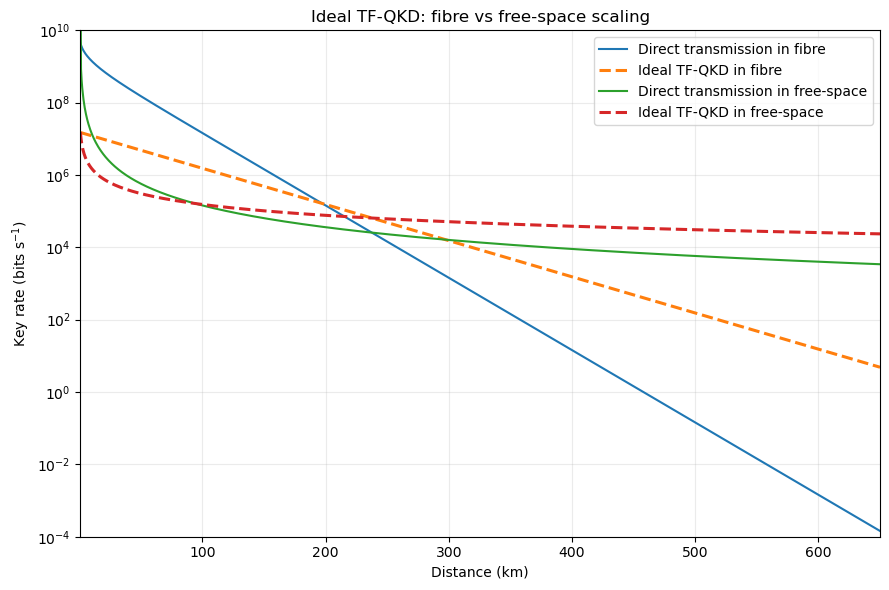

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def h2(x):
    x = np.clip(np.asarray(x, dtype=float), 1e-15, 1 - 1e-15)
    return -(x*np.log2(x) + (1-x)*np.log2(1-x))

# Common TF-QKD ideal parameters
clock = 1e9
M = 16
E_M = 1.275e-2
u_opt = 0.765

# Distance grid
L = np.linspace(1, 650, 1300)   # start at 1 km to avoid 1/0 in free-space model

# ---------- Fibre ----------
alpha_db_per_km = 0.2
eta_fibre = 10 ** (-alpha_db_per_km * L / 10.0)
eta_hat_fibre = np.sqrt(eta_fibre)

R_plob_fibre = clock * (-np.log2(np.clip(1 - eta_fibre, 1e-300, None)))
R_tf_fibre = clock * (u_opt * eta_hat_fibre / M) * (
    np.exp(-u_opt) * (1 - h2(E_M)) - h2(E_M)
)

# ---------- Free-space ----------
# Simple inverse-square model normalized so eta=1 at L0
L0 = 1.0   # km
eta0 = 1.0
eta_fs = np.minimum(eta0 * (L0 / L)**2, 1.0)

# Ideal TF-QKD free-space analogue: replace eta by eta_fs
eta_hat_fs = np.sqrt(eta_fs)

# "Direct-transmission bound-like" comparison:
# for small eta, PLOB ~ eta/ln2, so we use the exact same expression formally
R_plob_fs = clock * (-np.log2(np.clip(1 - eta_fs, 1e-300, None)))

# Ideal TF-QKD free-space analogue
R_tf_fs = clock * (u_opt * eta_hat_fs / M) * (
    np.exp(-u_opt) * (1 - h2(E_M)) - h2(E_M)
)

plt.figure(figsize=(9, 6))
ax = plt.gca()

ax.semilogy(L, R_plob_fibre, label="Direct transmission in fibre")
ax.semilogy(L, R_tf_fibre, "--", lw=2.2, label="Ideal TF-QKD in fibre")

ax.semilogy(L, R_plob_fs, label="Direct transmission in free-space")
ax.semilogy(L, R_tf_fs, "--", lw=2.2, label="Ideal TF-QKD in free-space")

ax.set_xlim(1, 650)
ax.set_ylim(1e-4, 1e10)
ax.set_xlabel("Distance (km)")
ax.set_ylabel(r"Key rate (bits s$^{-1}$)")
ax.set_title("Ideal TF-QKD: fibre vs free-space scaling")
ax.grid(True, which="both", alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

C:\Users\Ry\AppData\Local\Temp\ipykernel_21000\820885703.py:34: RuntimeWarning: divide by zero encountered in log2
  R_direct_fs = -np.log2(1 - eta_fs)


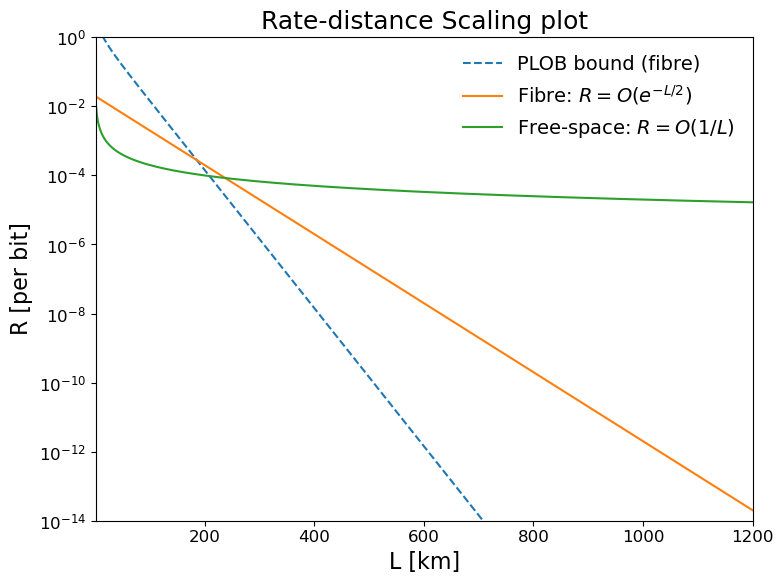

In [43]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 12})
plt.rc('axes', titlesize=18)
plt.rc('axes', labelsize=16)
# Distance axis (km)
L = np.linspace(1, 1200, 4000)   # start at 1 km to avoid division by zero

# -----------------------------
# 1) Fibre model
# -----------------------------
alpha_db_per_km = 0.2
eta_fibre = 10 ** (-alpha_db_per_km * L / 10.0)

# PLOB bound (rate per channel use)
R_plob_fibre = -np.log2(1 - eta_fibre)

# Simple sqrt(eta) protocol in fibre
# c just sets the vertical scale for illustration
c_fibre = 0.02
R_sqrt_fibre = c_fibre * np.sqrt(eta_fibre)

# -----------------------------
# 2) Free-space geometric model
# -----------------------------
# Very simple inverse-square model:
# eta_fs = eta0 * (L0 / L)^2
L0 = 1.0      # reference distance in km
eta0 = 1.0    # transmittance at L0
eta_fs = np.minimum(eta0 * (L0 / L)**2, 1.0)

# "Direct transmission" free-space comparison
# Using the same pure-loss-style bound formula for illustration
R_direct_fs = -np.log2(1 - eta_fs)

# Simple sqrt(eta) protocol in free-space
c_fs = 0.02
R_sqrt_fs = c_fs * np.sqrt(eta_fs)

# -----------------------------
# Plot
# -----------------------------
plt.figure(figsize=(8, 6))

plt.semilogy(L, R_plob_fibre, '--',label='PLOB bound (fibre)')
plt.semilogy(L, R_sqrt_fibre, label=r'Fibre: $R=O(e^{-L/2})$')
plt.semilogy(L, R_sqrt_fs, label=r'Free-space: $R=O(1/L)$')

plt.xlim(1, 1200)
plt.ylim(1e-14, 1)
plt.xlabel('L [km]')
plt.ylabel('R [per bit]')
plt.title('Rate-distance Scaling plot')
plt.legend(fontsize="14",frameon=False)
plt.tight_layout()
plt.savefig("RateDistanceScalingPlot.pdf", dpi=300, bbox_inches="tight")
plt.show()

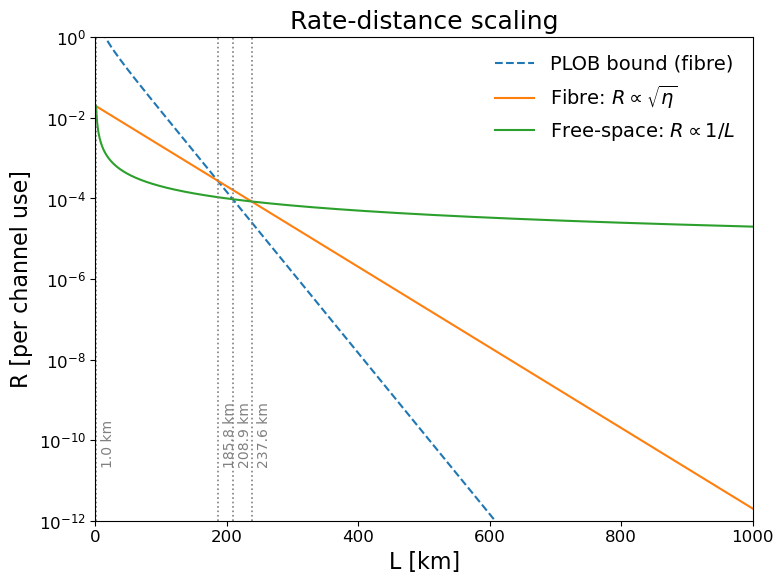

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 12})
plt.rc('axes', titlesize=18)
plt.rc('axes', labelsize=16)

# Distance axis (km)
# Start slightly above 0 to avoid division-by-zero in the free-space model
L = np.linspace(1e-3, 1000, 4000)

# -----------------------------
# 1) Fibre model
# -----------------------------
alpha_db_per_km = 0.2
eta_fibre = 10 ** (-alpha_db_per_km * L / 10.0)

# PLOB bound (rate per channel use)
R_plob_fibre = -np.log2(1 - eta_fibre)

# Simple sqrt(eta) protocol in fibre
c_fibre = 0.02
R_sqrt_fibre = c_fibre * np.sqrt(eta_fibre)

# -----------------------------
# 2) Free-space geometric model
# -----------------------------
# Very simple inverse-square model:
# eta_fs = eta0 * (L0 / L)^2
L0 = 1.0      # reference distance in km
eta0 = 1.0    # transmittance at L0
eta_fs = np.minimum(eta0 * (L0 / L)**2, 1.0)

# Simple sqrt(eta) protocol in free-space
c_fs = 0.02
R_sqrt_fs = c_fs * np.sqrt(eta_fs)

# -----------------------------
# Find curve crossings
# -----------------------------
def find_crossings(x, y1, y2):
    """Return approximate x-values where y1 and y2 cross."""
    diff = y1 - y2
    idx = np.where(np.sign(diff[:-1]) != np.sign(diff[1:]))[0]
    x_cross = []

    for i in idx:
        # Linear interpolation for a better crossing estimate
        x1, x2 = x[i], x[i+1]
        d1, d2 = diff[i], diff[i+1]
        xc = x1 - d1 * (x2 - x1) / (d2 - d1)
        x_cross.append(xc)

    return x_cross

crossings = []

# PLOB fibre vs sqrt fibre
for xc in find_crossings(L, R_plob_fibre, R_sqrt_fibre):
    if 0 <= xc <= 1000:
        crossings.append((xc, 'PLOB = fibre $\\sqrt{\\eta}$'))

# PLOB fibre vs free-space sqrt
for xc in find_crossings(L, R_plob_fibre, R_sqrt_fs):
    if 0 <= xc <= 1000:
        crossings.append((xc, 'PLOB = free-space $\\sqrt{\\eta}$'))

# Fibre sqrt vs free-space sqrt
for xc in find_crossings(L, R_sqrt_fibre, R_sqrt_fs):
    if 0 <= xc <= 1000:
        crossings.append((xc, 'fibre $\\sqrt{\\eta}$ = free-space $\\sqrt{\\eta}$'))

# Remove near-duplicate crossings
filtered_crossings = []
tol = 1.0  # km
for xc, label in sorted(crossings, key=lambda t: t[0]):
    if not filtered_crossings or abs(xc - filtered_crossings[-1][0]) > tol:
        filtered_crossings.append((xc, label))

# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(8, 6))

ax.semilogy(L, R_plob_fibre, '--', label='PLOB bound (fibre)')
ax.semilogy(L, R_sqrt_fibre, label=r'Fibre: $R \propto \sqrt{\eta}$')
ax.semilogy(L, R_sqrt_fs, label=r'Free-space: $R \propto 1/L$')

# Vertical lines at crossings
for xc, label in filtered_crossings:
    ax.axvline(x=xc, color='gray', linestyle=':', linewidth=1.2)
    ax.text(
        xc + 8, 2e-11,
        f'{xc:.1f} km',
        rotation=90,
        va='bottom',
        ha='left',
        fontsize=10,
        color='gray'
    )

ax.set_xlim(0, 1000)
ax.set_ylim(1e-12, 1)
ax.set_xlabel('L [km]')
ax.set_ylabel('R [per channel use]')
ax.set_title('Rate-distance scaling')
ax.legend(fontsize=14, frameon=False)

plt.tight_layout()
plt.savefig("RateDistanceScalingPlot.pdf", dpi=300, bbox_inches="tight")
plt.show()

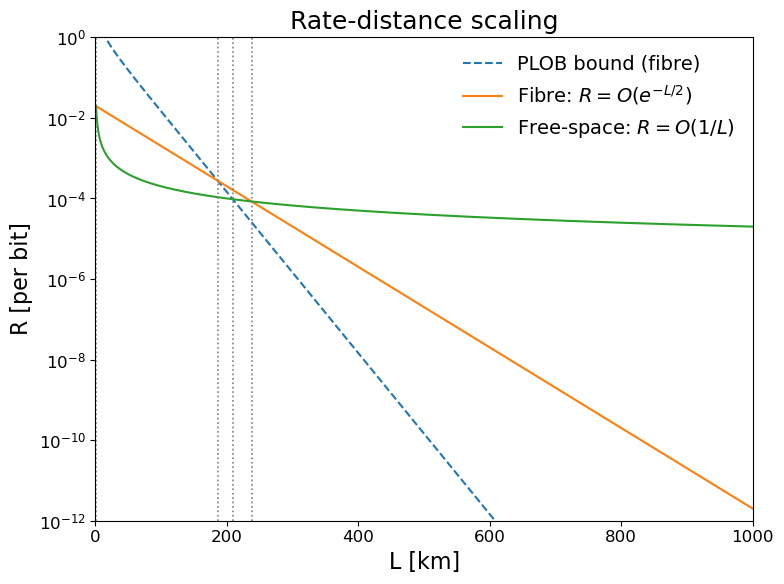

In [7]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 12})
plt.rc('axes', titlesize=18)
plt.rc('axes', labelsize=16)

# Distance axis (km)
L = np.linspace(1e-3, 1000, 4000)

# -----------------------------
# 1) Fibre model
# -----------------------------
alpha_db_per_km = 0.2
eta_fibre = 10 ** (-alpha_db_per_km * L / 10.0)

# PLOB bound (rate per channel use)
R_plob_fibre = -np.log2(1 - eta_fibre)

# Simple sqrt(eta) protocol in fibre
c_fibre = 0.02
R_sqrt_fibre = c_fibre * np.sqrt(eta_fibre)

# -----------------------------
# 2) Free-space geometric model
# -----------------------------
L0 = 1.0
eta0 = 1.0
eta_fs = np.minimum(eta0 * (L0 / L)**2, 1.0)

# Simple sqrt(eta) protocol in free-space
c_fs = 0.02
R_sqrt_fs = c_fs * np.sqrt(eta_fs)

# -----------------------------
# Find curve crossings
# -----------------------------
def find_crossings(x, y1, y2):
    diff = y1 - y2
    idx = np.where(np.sign(diff[:-1]) != np.sign(diff[1:]))[0]
    x_cross = []
    for i in idx:
        x1, x2 = x[i], x[i+1]
        d1, d2 = diff[i], diff[i+1]
        xc = x1 - d1 * (x2 - x1) / (d2 - d1)
        x_cross.append(xc)
    return x_cross

crossings = []

for xc in find_crossings(L, R_plob_fibre, R_sqrt_fibre):
    if 0 <= xc <= 1000:
        crossings.append(xc)

for xc in find_crossings(L, R_plob_fibre, R_sqrt_fs):
    if 0 <= xc <= 1000:
        crossings.append(xc)

for xc in find_crossings(L, R_sqrt_fibre, R_sqrt_fs):
    if 0 <= xc <= 1000:
        crossings.append(xc)

# Remove near-duplicate crossings
filtered_crossings = []
tol = 1.0  # km
for xc in sorted(crossings):
    if not filtered_crossings or abs(xc - filtered_crossings[-1]) > tol:
        filtered_crossings.append(xc)

# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(8, 6))

ax.semilogy(L, R_plob_fibre, '--', label='PLOB bound (fibre)')
ax.semilogy(L, R_sqrt_fibre, label=r'Fibre: $R=O(e^{-L/2})$')
ax.semilogy(L, R_sqrt_fs, label=r'Free-space: $R=O(1/L)$')

# Vertical lines at crossings, no text labels
for xc in filtered_crossings:
    ax.axvline(x=xc, color='gray', linestyle=':', linewidth=1.2)

ax.set_xlim(0, 1000)
ax.set_ylim(1e-12, 1)
ax.set_xlabel('L [km]')
ax.set_ylabel('R [per bit]')
ax.set_title('Rate-distance scaling')
ax.legend(fontsize=14, frameon=False)

plt.tight_layout()
plt.savefig("RateDistanceScalingPlot.pdf", dpi=300, bbox_inches="tight")
plt.show()